In [9]:
#!pip install postcell

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
%cd /content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git

!git status

/content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git
Refresh index: 100% (6/6), done.
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Computer Vision/

nothing added to commit but untracked files present (use "git add" to track)


In [10]:
%reload_ext postcell
%postcell register

PostCell loaded
Loading config file from /content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git/postcell.conf
Registered user Fara_Olivia at https://postcell.io/post_cell


In [11]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

####1. Upload foto

Saving 338185-basic-pancakes-09-00b18f8418fd4e52bb2050173d083d04.jpg to 338185-basic-pancakes-09-00b18f8418fd4e52bb2050173d083d04.jpg


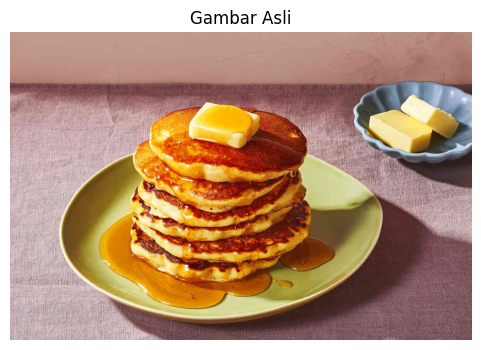

Ukuran gambar: (1500, 1000)


In [13]:
# Upload foto dari komputer
uploaded = files.upload()
filename = next(iter(uploaded))

# Baca foto dan ubah ke format RGB
image = Image.open(filename).convert("RGB")

plt.figure(figsize=(6, 4))
plt.imshow(image)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

print("Ukuran gambar:", image.size)

Foto yang kita lihat sebenarnya bisa direpresentasikan sebagai kumpulan angka. Komputer tidak memahami gambar seperti manusia melihat botol atau kaleng; komputer menerima data numerik yang dapat diproses.

###2. Melihat Gambar Sebagai Array

In [19]:
# Ubah gambar menjadi array NumPy
%%postcell UbahGambarJadiArray
img_array = np.array(image)

Cell posted for evaluation


In [20]:
print("Bentuk array:", img_array.shape)
print("Tiga dimensi: tinggi, lebar, kanal warna")

Bentuk array: (1000, 1500, 3)
Tiga dimensi: tinggi, lebar, kanal warna


In [21]:
print("\nNilai RGB piksel di pojok kiri atas:")
print(img_array[0, 0])


Nilai RGB piksel di pojok kiri atas:
[194 155 140]


In [22]:
print("\nNilai RGB untuk area 3 x 3 piksel:")
print(img_array[:3, :3, :])


Nilai RGB untuk area 3 x 3 piksel:
[[[194 155 140]
  [194 155 140]
  [194 155 140]]

 [[194 155 140]
  [194 155 140]
  [194 155 140]]

 [[194 155 140]
  [194 155 140]
  [194 155 140]]]


###3. Memisahkan Kanal RGB

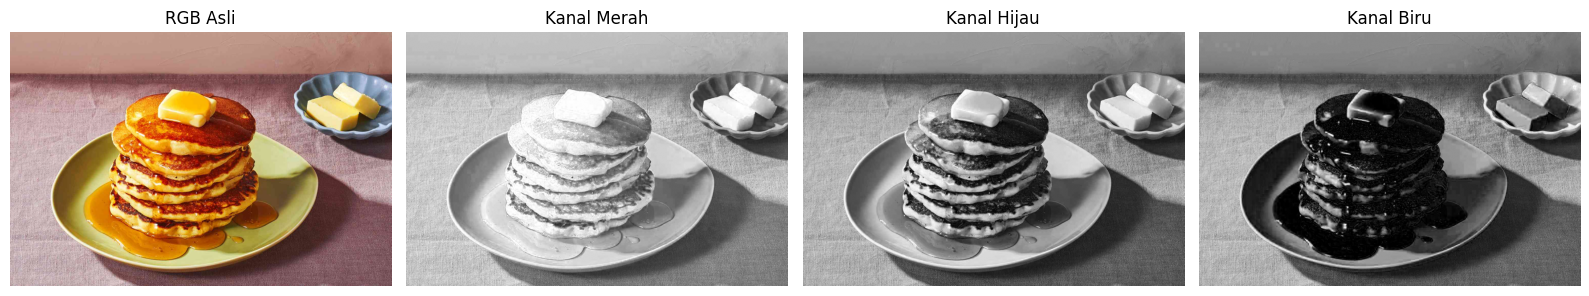

In [23]:
red = img_array[:, :, 0]
green = img_array[:, :, 1]
blue = img_array[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_array)
axes[0].set_title("RGB Asli")

axes[1].imshow(red, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Kanal Merah")

axes[2].imshow(green, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Kanal Hijau")

axes[3].imshow(blue, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Kanal Biru")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Mengapa ketika kita memisahkan kanal merah, hijau, dan biru, hasilnya terlihat seperti gambar hitam-putih?

###4. Memperbesar Piksel

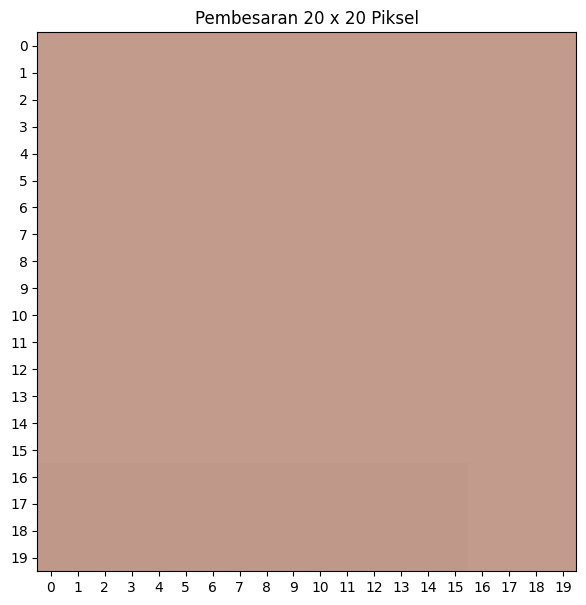

In [24]:
# Ambil sebagian kecil area gambar
patch = img_array[:20, :20, :]

plt.figure(figsize=(7, 7))
plt.imshow(patch, interpolation="nearest")
plt.title("Pembesaran 20 x 20 Piksel")
plt.xticks(range(20))
plt.yticks(range(20))
plt.grid(False)
plt.show()

###5. Apa yang terjadi jika resolusi diperkecil drastis?

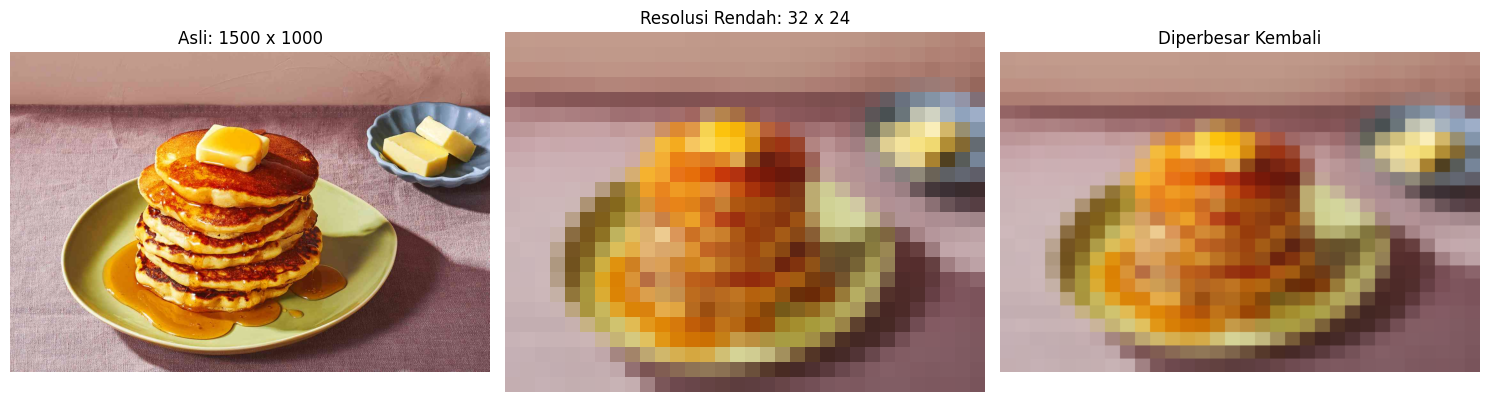

In [25]:
# Perkecil gambar menjadi 32 x 24 piksel
small = image.resize((32, 24), Image.Resampling.BILINEAR)

# Perbesar kembali untuk memperlihatkan pikselasi
pixelated = small.resize(
    image.size,
    Image.Resampling.NEAREST
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title(f"Asli: {image.width} x {image.height}")

axes[1].imshow(small)
axes[1].set_title("Resolusi Rendah: 32 x 24")

axes[2].imshow(pixelated)
axes[2].set_title("Diperbesar Kembali")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Perhatikan perbedaannya: gambar beresolusi rendah menyimpan jauh lebih sedikit sampel piksel. Ketika diperbesar kembali, kotak-kotak piksel menjadi terlihat dan detail halus sulit dikenali.

In [26]:
width, height = 640, 480
channels = 3
bits_per_channel = 8

total_pixels = width * height
total_values = total_pixels * channels
total_bytes = total_values * (bits_per_channel // 8)

print("Total piksel:", total_pixels)
print("Total nilai RGB:", total_values)
print("Ukuran data mentah:", total_bytes, "byte")
print("Ukuran dalam KiB:", total_bytes / 1024)

Total piksel: 307200
Total nilai RGB: 921600
Ukuran data mentah: 921600 byte
Ukuran dalam KiB: 900.0


Perlu ditekankan bahwa ukuran data mentah berbeda dengan ukuran file JPEG atau PNG. JPEG umumnya menggunakan kompresi lossy, sedangkan PNG menggunakan kompresi lossless. Ukuran file akhirnya bergantung pada isi gambar dan pengaturan penyimpanan.

Pertanyaan refleksi untuk diskusi kelas:
1. Mengapa gambar digital dapat diproses menggunakan operasi matematika?
2. Apa perbedaan antara jumlah piksel dan jumlah nilai kanal RGB?
3. Apa yang terjadi pada detail gambar ketika resolusinya diperkecil secara drastis?
4. Mengapa gambar beresolusi tinggi dapat membutuhkan lebih banyak memori?